# Adversarial Search: Playing "Mean" Connect 4


## Instructions

Total Points: Undegraduates 10, graduate students 11

Complete this notebook and submit it. The notebook needs to be a complete project report with your implementation, documentation including a short discussion of how your implementation works and your design choices, and experimental results (e.g., tables and charts with simulation results) with a short discussion of what they mean. Use the provided notebook cells and insert additional code and markdown cells as needed.

## Introduction

You will implement different versions of agents that play "Mean" Connect 4:

> "Connect 4 is a two-player connection board game, in which the players choose a color and then take turns dropping colored discs into a seven-column, six-row vertically suspended grid. The pieces fall straight down, occupying the lowest available space within the column. The objective of the game is to be the first to form a horizontal, vertical, or diagonal line of four of one's own discs." (see [Connect Four on Wikipedia](https://en.wikipedia.org/wiki/Connect_Four))

> **The mean part:** This game has an additional rule. Every time it is a player's turn, the player can decide to instead of playing a new disk, take a bottom row disk of the opponent and place it in any column. All disks above the removed disk will fall down one position. Note that a player can only move an _opponent's disc_ that is in the _bottom row_ of the board.

Note that normal [Connect-4 has been solved](https://en.wikipedia.org/wiki/Connect_Four#Mathematical_solution)
in 1988. A connect-4 solver with a discussion of how to solve different parts of the problem can be found here: https://connect4.gamesolver.org/en/

Student Name: Lê Minh Hiếu (MSSV 3124720023) – Nhóm 31

I have used the following AI tools: Claude Code (Anthropic)

Notebook này dùng lại phần lớn code của [assignment_connect4.ipynb](assignment_connect4.ipynb) (Bài 8). Code được chép lại vào đây để notebook chạy độc lập,
và sửa những chỗ khác do luật "Mean": `actions()`, `result()`, `check_board()`, thêm xử lý lặp trạng thái trong tìm kiếm, và thêm một hàm heuristic có tính tới luật Mean.

## Task 1: Defining the Search Problem [1 point]

Define the components of the search problem associated with this game:

* Initial state
* Actions
* Transition model
* Test for the terminal state
* Utility for terminal states

**Bài toán tìm kiếm đối kháng cho Mean Connect 4** (Đỏ = `1` đi trước, Vàng = `-1`; bàn cờ numpy, hàng `0` ở trên cùng, hàng cuối là hàng **đáy**):

* **Trạng thái ban đầu:** bàn rỗng $r \times c$ (chuẩn $6 \times 7$), Đỏ đi trước.
  Khác Connect 4 thường: **bàn cờ không cho biết ai đi tiếp**, vì nước Mean không làm thay đổi số quân của mỗi bên.
  Vì vậy trạng thái thật sự là cặp (bàn cờ, người đi tiếp), và mọi hàm đều nhận thêm tham số `player`.
* **Actions(s, player):** có hai loại nước đi:
  1. *Thả quân* vào một cột còn chỗ (giống Connect 4), ký hiệu bằng số cột `c`;
  2. *Nước Mean*: lấy một quân **của đối thủ** đang nằm ở **hàng đáy** cột `f`, đặt nó vào cột `t` bất kỳ còn chỗ, ký hiệu `(f, t)`.
     Sau khi lấy quân, cột `f` luôn có thêm một chỗ, nên `t = f` cũng hợp lệ (quân đó lên nằm trên cùng cột `f`).
* **Result(s, a)** (mô hình chuyển trạng thái): thả quân thì giống Connect 4. Nước Mean thì bỏ quân ở đáy cột `f`,
  các quân phía trên cột `f` rơi xuống 1 ô, rồi thả quân vừa lấy (vẫn là quân của đối thủ) vào cột `t`.
* **Terminal(s):** một bên có 4 quân liên tiếp, hoặc bàn đầy. Luật gốc không nói rõ hai trường hợp, nên nhóm quy ước:
  * Nước Mean làm quân rơi xuống, nên **cả hai bên có thể cùng có 4 quân liên tiếp** sau một nước đi: tính là **hòa**.
  * Khi bàn đầy, người chơi vẫn có thể đi nước Mean (lấy quân đáy rồi trả về đúng cột đó), nên ván có thể kéo dài mãi:
    bàn đầy được tính là **hòa**, giống Connect 4. Ngoài ra môi trường `play()` tính hòa nếu ván dài quá `max_moves` nước.
* **Utility(s, player):** `+1` nếu `player` thắng, `-1` nếu thua, `0` nếu hòa; `None` nếu chưa kết thúc.

Các hàm được cài đặt ở Task 2.

How big is the state space? Give an estimate and explain it.

**Kích thước không gian trạng thái:**

* Bàn cờ vẫn phải tuân theo trọng lực (quân xếp liền từ đáy lên), nên các bàn cờ hợp lệ là tập con của các bàn Connect 4 có cùng số quân mỗi bên trở xuống:
  cận trên $127^7 \approx 5.3 \times 10^{14}$ (mỗi cột là một chuỗi Đỏ/Vàng dài 0–6).
* Khác Connect 4 thường: nước Mean **sắp xếp lại** quân mà không thêm quân, nên với cùng số quân, gần như mọi cách sắp xếp màu theo cột đều đạt được,
  kể cả những bàn không thể xuất hiện trong Connect 4 thường (ví dụ bàn đã có hàng 4 của một bên được tạo ra khi quân rơi).
  Ngoài ra trạng thái phải kèm người đi tiếp, nên số trạng thái nhân thêm khoảng 2.
* Ước lượng: cỡ $10^{13}$–$10^{15}$ trạng thái, cùng bậc hoặc lớn hơn Connect 4 thường ($4.5 \times 10^{12}$).
  Không gian trạng thái không lớn hơn quá nhiều; khó khăn chính nằm ở cây trò chơi (bên dưới).

In [1]:
print(f"Cận trên có trọng lực: 127^7 = {127**7:.2e}; nhân 2 cho người đi tiếp: {2 * 127**7:.2e}")

Cận trên có trọng lực: 127^7 = 5.33e+14; nhân 2 cho người đi tiếp: 1.07e+15


How big is the game tree that minimax search will go through? Give an estimate and explain it.

**Kích thước cây trò chơi:**

* **Hệ số rẽ nhánh lớn hơn nhiều:** ngoài tối đa 7 nước thả quân, mỗi quân của đối thủ ở hàng đáy cho thêm tới 7 nước Mean.
  Nếu đối thủ có $m$ quân ở hàng đáy thì có tới $7 + 7m$ nước đi, tối đa $7 + 7 \cdot 7 = 56$.
* **Cây có thể dài vô hạn:** nước Mean không thêm quân nên trạng thái có thể lặp lại (A lấy quân, B lấy lại...).
  Minimax thuần sẽ không dừng, nên phải xử lý lặp (ở đây: trạng thái lặp lại trên đường đi hiện tại được tính là hòa) hoặc giới hạn số nước.
* Dù đã chặn lặp, mỗi ván vẫn có thể dài hơn 42 nước rất nhiều. Với hệ số rẽ nhánh trung bình $b$ và độ dài ván $d$,
  cây có khoảng $b^d$ nút. Ở cuối Task 2 có thí nghiệm đo $b$ và $d$ trung bình khi hai Random đấu nhau, so với Connect 4 thường.

## Task 2: Game Environment and Random Agent [3 point]

You can use a numpy character array as the board. Note that the following function can create boards of different sizes.

In [2]:
import numpy as np

def empty_board(shape=(6, 7)):
    return np.full(shape=shape, fill_value=0)

print(empty_board())

[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


Instead of colors (red and yellow), you can use 1 and -1 to represent the players Max and Min. Make sure that your agent functions all have the from: `agent_type(board, player = 1)`, where board is the current board position and player is the player (1, -1) whose next move it is and who the agent should play.

Visualization code by Randolph Rankin:

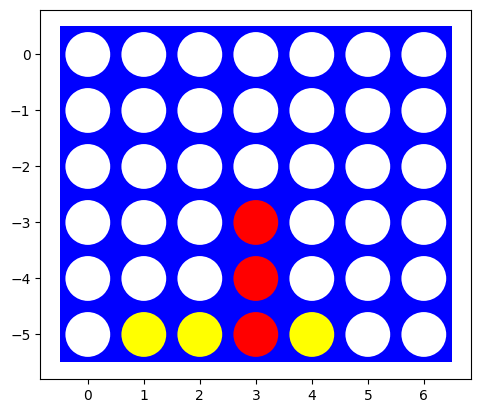

In [3]:
import matplotlib.pyplot as plt

def visualize(board):
    plt.axes()
    rectangle=plt.Rectangle((-0.5,len(board)*-1+0.5),len(board[0]),len(board),fc='blue')
    circles=[]
    for i,row in enumerate(board):
        for j,val in enumerate(row):
            color='white' if val==0 else 'red' if val==1 else 'yellow'
            circles.append(plt.Circle((j,i*-1),0.4,fc=color))

    plt.gca().add_patch(rectangle)
    for circle in circles:
        plt.gca().add_patch(circle)

    plt.axis('scaled')
    plt.show()
    
board = [[0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0, 0, 0, 1, 0, 0, 0],
         [0,-1,-1, 1,-1, 0, 0]]

visualize(board)

Implement helper functions for:

* The transition model $result(s, a)$.
* The utility function $utility(s)$.
* Check for terminal states $terminal(s)$.
* A check for available actions in each state $actions(s)$.

Make sure that all these functions work with boards of different sizes (number of columns and rows).

In [4]:
import numpy as np

CONNECT = 4   # số quân liên tiếp cần để thắng (bàn nhỏ có thể dùng 3)

def actions(board, player = 1):
    """Các nước đi hợp lệ của player:
    * thả quân: số nguyên c = cột còn chỗ;
    * nước "Mean": tuple (f, t) = lấy quân của đối thủ ở hàng đáy cột f, đặt vào cột t.
      Sau khi lấy quân, cột f có thêm một chỗ trống, nên t = f luôn hợp lệ (quân về nằm trên cùng cột f)."""
    cols = board.shape[1]
    drops = [c for c in range(cols) if board[0, c] == 0]
    means = [(f, t) for f in range(cols) if board[-1, f] == -player
                    for t in range(cols) if t == f or board[0, t] == 0]
    return drops + means

def result(board, player, action):
    """Mô hình chuyển trạng thái cho cả hai loại nước đi."""
    board = board.copy()
    if isinstance(action, tuple):           # nước Mean
        f, t = action
        if board[-1, f] != -player:
            raise Exception(f"Illegal action {action} by player {player}!")
        board[1:, f] = board[:-1, f].copy()  # các quân phía trên rơi xuống 1 ô
        board[0, f] = 0
        disc, col = -player, t               # quân lấy ra vẫn là quân của đối thủ
    else:                                    # thả quân của mình
        disc, col = player, action
    if board[0, col] != 0:
        raise Exception(f"Illegal action {action} by player {player}!")
    row = np.nonzero(board[:, col] == 0)[0][-1]   # ô trống thấp nhất của cột
    board[row, col] = disc
    return board

WINDOWS = {}

def get_windows(shape, k = None):
    """Chỉ số (trên board.ravel()) của mọi đoạn k ô liên tiếp (ngang, dọc, 2 chéo). Tính một lần cho mỗi kích thước."""
    k = CONNECT if k is None else k
    if (shape, k) not in WINDOWS:
        rows, cols = shape
        idx = np.arange(rows * cols).reshape(shape)
        w = []
        for i in range(rows):
            for j in range(cols):
                for di, dj in [(0, 1), (1, 0), (1, 1), (1, -1)]:
                    ii = [i + di * s for s in range(k)]
                    jj = [j + dj * s for s in range(k)]
                    if ii[-1] < rows and 0 <= min(jj) and max(jj) < cols:
                        w.append(idx[ii, jj])
        WINDOWS[(shape, k)] = np.array(w, dtype = int).reshape(-1, k)
    return WINDOWS[(shape, k)]

def check_board(board):
    """1 hoặc -1 (người thắng), 'd' (hòa) hoặc 'n' (chưa kết thúc).
    Nước Mean có thể làm cả hai bên cùng có CONNECT quân liên tiếp: trường hợp này tính là hòa.
    Bàn đầy cũng tính là hòa (khi đó chỉ còn nước Mean trả quân về đúng cột cũ, ván có thể kéo dài vô hạn)."""
    s = board.ravel()[get_windows(board.shape)].sum(axis = 1)
    red, yellow = np.any(s == CONNECT), np.any(s == -CONNECT)
    if red and yellow: return 'd'
    if red: return 1
    if yellow: return -1
    if np.all(board[0] != 0): return 'd'
    return 'n'

def terminal(board):
    return check_board(board) != 'n'

def utility(board, player = 1):
    """+1 thắng, 0 hòa, -1 thua (góc nhìn player). None nếu chưa kết thúc."""
    goal = check_board(board)
    if goal == player: return +1
    if goal == 'd': return 0
    if goal == -player: return -1
    return None

Các hàm làm việc với bàn cờ kích thước bất kỳ. `check_board()` dùng cách của Bài 8: tính sẵn mọi đoạn `CONNECT` ô liên tiếp rồi cộng bằng numpy.
`CONNECT` là biến toàn cục để có thể đổi sang luật nối 3 trên bàn nhỏ (Task 3).

Thử các hàm, đặc biệt là nước Mean:

Nước đi của Đỏ (1): [0, 1, 2, 3, 4, 5, 6, (1, 0), (1, 1), (1, 2), (1, 3), (1, 4), (1, 5), (1, 6), (2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (2, 5), (2, 6), (4, 0), (4, 1), (4, 2), (4, 3), (4, 4), (4, 5), (4, 6)]
Số nước đi của Đỏ: 28 | của Vàng: 14
[[ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0 -1  0  0  0]
 [ 0  0  0  1  0  0  0]
 [ 0  0  0  1  0  0  0]
 [ 0 -1  0  1 -1  0  0]]


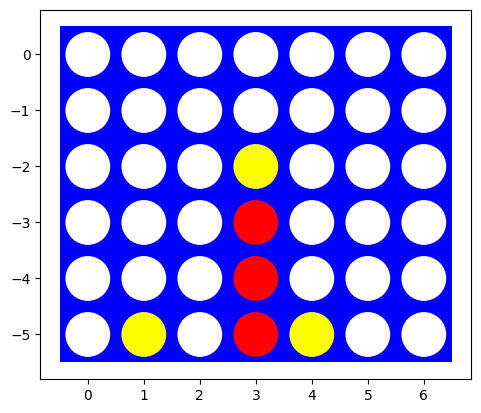

[[ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0]
 [ 0  0  0 -1  0  0  0]
 [ 0  0  0  1  0  0  0]
 [ 1 -1  0  1 -1  0  0]]
check_board: n | utility(1): None


In [5]:
board = np.array([[ 0,  0,  0,  0,  0,  0,  0],
                  [ 0,  0,  0,  0,  0,  0,  0],
                  [ 0,  0,  0,  0,  0,  0,  0],
                  [ 0,  0,  0,  1,  0,  0,  0],
                  [ 0,  0,  0,  1,  0,  0,  0],
                  [ 0, -1, -1,  1, -1,  0,  0]])
print("Nước đi của Đỏ (1):", actions(board, 1))
print("Số nước đi của Đỏ:", len(actions(board, 1)), "| của Vàng:", len(actions(board, -1)))

# Đỏ lấy quân Vàng ở đáy cột 2, đặt vào cột 3 (trên đỉnh tháp Đỏ)
board2 = result(board, 1, (2, 3))
print(board2)
visualize(board2)

# Vàng lấy quân Đỏ ở đáy cột 3: 2 quân Đỏ và 1 quân Vàng phía trên rơi xuống 1 ô; quân Đỏ được đặt vào cột 0
board3 = result(board2, -1, (3, 0))
print(board3)
print("check_board:", check_board(board3), "| utility(1):", utility(board3, 1))

Implement an agent that plays randomly. Make sure the agent function receives as the percept the board and returns a valid action. Use an agent function definition with the following signature (arguments):

`def random_player(board, player = None): ...`

The argument `player` is used for agents that do not store what side they are playing. The value passed on bt yhe environment should be 1 ot -1 for playerred and yellow, respectively.  See [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) for an example.

In [6]:
def random_player(board, player = None):
    """Chọn ngẫu nhiên một nước hợp lệ (thả quân hoặc Mean) với xác suất bằng nhau.
    Cần biết player để biết quân nào ở hàng đáy là của đối thủ; môi trường luôn truyền player."""
    if player is None: player = 1
    acts = actions(board, player)
    return acts[np.random.randint(len(acts))]

def play(red, yellow, N = 100, shape = (6, 7), max_moves = 200, show_final_board = False, return_stats = False):
    """Cho hai agent đấu N ván. red (1) đi trước. Vì nước Mean không thêm quân,
    ván có thể lặp vô hạn: quá max_moves nước thì tính hòa.
    return_stats = True trả thêm độ dài ván trung bình và tỷ lệ nước Mean."""
    results = {1: 0, -1: 0, 'd': 0}
    lengths, n_mean = [], 0

    for i in range(N):
        board = empty_board(shape)
        player, agent = 1, red

        for m in range(max_moves):
            a = agent(board, player)
            n_mean += isinstance(a, tuple)
            board = result(board, player, a)

            win = check_board(board)
            if win != 'n': break
            player, agent = -player, (yellow if player == 1 else red)
        else:
            win = 'd'           # quá số nước tối đa

        results[win] += 1
        lengths.append(m + 1)
        if show_final_board: visualize(board)

    if return_stats:
        return results, {"avg_length": np.mean(lengths), "mean_move_share": n_mean / sum(lengths)}
    return results

Let two random agents play against each other 1000 times. Look at the [Experiments section for tic-tac-toe](https://nbviewer.org/github/mhahsler/CS7320-AI/blob/master/Games/tictactoe_and_or_tree_search.ipynb#Experiments) to see how the environment uses the agent functions to play against each other.

How often does each player win? Is the result expected?

In [7]:
print("Random (Đỏ, đi trước) vs. Random (Vàng), Mean Connect 4 bàn 6x7:")
CONNECT = 4
%time random_results, random_stats = play(random_player, random_player, N = 1000, return_stats = True)
display(random_results)
print(f"Độ dài ván TB: {random_stats['avg_length']:.1f} nước | tỷ lệ nước Mean: {random_stats['mean_move_share']:.1%}")

Random (Đỏ, đi trước) vs. Random (Vàng), Mean Connect 4 bàn 6x7:


CPU times: user 601 ms, sys: 9.61 ms, total: 611 ms
Wall time: 623 ms


{1: 776, -1: 215, 'd': 9}

Độ dài ván TB: 25.0 nước | tỷ lệ nước Mean: 56.5%


In [8]:
# So sánh với Connect 4 thường: Random chỉ được thả quân
def random_drop_player(board, player = None):
    """Random chỉ thả quân (tức là chơi Connect 4 thường trên cùng môi trường)."""
    return np.random.choice([a for a in actions(board, 1) if not isinstance(a, tuple)])

%time c4_results, c4_stats = play(random_drop_player, random_drop_player, N = 1000, return_stats = True)
display(c4_results)
print(f"Connect 4 thường - độ dài ván TB: {c4_stats['avg_length']:.1f} nước")

CPU times: user 685 ms, sys: 91.6 ms, total: 777 ms
Wall time: 796 ms


{1: 551, -1: 445, 'd': 4}

Connect 4 thường - độ dài ván TB: 21.2 nước


**Nhận xét:** * **Mean Connect 4:** Đỏ (đi trước) thắng **776/1000** ván (77,6%), Vàng thắng 215, hòa 9.
  Trên cùng môi trường nhưng chỉ cho thả quân (Connect 4 thường), Đỏ thắng 551/1000 (55,1%).
  **Lợi thế đi trước lớn hơn hẳn** so với Connect 4 thường (Bài 8 cũng đo được 54,1%).
* **56,5%** số nước của Random là nước Mean, vì mỗi quân đối thủ ở hàng đáy cho thêm tới 7 nước Mean, nhiều hơn số nước thả quân.
  Ván dài hơn một chút: trung bình 25,0 nước so với 21,2.
* Kết quả không hoàn toàn như dự đoán. Nhóm chưa chứng minh được nguyên nhân. Giả thuyết: nước Mean không thêm quân cho người đi,
  nên người thả quân nhiều hơn (thường là Đỏ, vì đi trước) có nhiều quân trên bàn hơn và nhiều đường nối 4 hơn. Ngoài ra, quân rơi xuống sau một nước Mean có thể vô tình hoàn thành hàng 4.

In [9]:
# Hệ số rẽ nhánh trung bình (Task 1): đếm số nước đi hợp lệ ở mọi trạng thái gặp trong 200 ván Random vs. Random
def branching(player_fun, N = 200, shape = (6, 7)):
    counts = []
    for i in range(N):
        board, player = empty_board(shape), 1
        for m in range(200):
            acts = actions(board, player) if player_fun is random_player else [a for a in actions(board, player) if not isinstance(a, tuple)]
            counts.append(len(acts))
            board = result(board, player, player_fun(board, player))
            if terminal(board): break
            player = -player
    return np.mean(counts), np.max(counts)

b_mean, b_max = branching(random_player)
b_c4, b_c4_max = branching(random_drop_player)
print(f"Mean Connect 4: hệ số rẽ nhánh TB {b_mean:.1f} (lớn nhất {b_max}), độ dài ván TB {random_stats['avg_length']:.1f}")
print(f"Connect 4     : hệ số rẽ nhánh TB {b_c4:.1f} (lớn nhất {b_c4_max}), độ dài ván TB {c4_stats['avg_length']:.1f}")
print(f"Ước lượng số nút cây (b^d): Mean {b_mean ** random_stats['avg_length']:.1e} | Connect 4 {b_c4 ** c4_stats['avg_length']:.1e}")

Mean Connect 4: hệ số rẽ nhánh TB 20.7 (lớn nhất 49), độ dài ván TB 25.0
Connect 4     : hệ số rẽ nhánh TB 6.7 (lớn nhất 7), độ dài ván TB 21.2
Ước lượng số nút cây (b^d): Mean 8.6e+32 | Connect 4 4.1e+17


**Nhận xét:** * Hệ số rẽ nhánh trung bình của Mean Connect 4 là **20,7** (lớn nhất 49), so với **6,7** (lớn nhất 7) của Connect 4, **gấp khoảng 3 lần**.
* Ước lượng thô $b^d$ với độ dài ván trung bình: khoảng $8.6 \times 10^{32}$ nút cho Mean, so với $4.1 \times 10^{17}$ cho Connect 4,
  lớn hơn khoảng $10^{15}$ lần. Đây mới tính ván ngẫu nhiên; ván giữa các agent mạnh có thể dài hơn nhiều vì hai bên liên tục "lấy quân" của nhau.

## Task 3: Minimax Search with Alpha-Beta Pruning [3 points]

### Implement the search starting.

Implement the search starting from a given board and specifying the player and put it into an agent function.
You can use code from the [tic-tac-toe example](tictactoe_alpha_beta_tree_search.ipynb).

__Notes:__ 
* Make sure that all your agent functions have a signature consistent with the random agent above.
* The search space for a $6 \times 7$ board is large. You can experiment with smaller boards (the smallest is $4 \times 4$) and/or changing the winning rule to connect 3 instead of 4.

In [10]:
import math
import time

# global variables
DEBUG = 1          # 1 ... in số nút, 2 ... in từng nút
COUNT = 0
TIME_LIMIT = None  # giới hạn thời gian (giây) chỉ dùng cho thí nghiệm đo thời gian
DEADLINE = None

def alpha_beta_search(board, player = 1, order = None):
    """Minimax search với alpha-beta pruning tới trạng thái kết thúc.
    Vì nước Mean có thể đưa ván về trạng thái cũ, trạng thái lặp lại trên đường đi hiện tại được tính là hòa (0),
    nhờ vậy cây tìm kiếm luôn hữu hạn."""
    global DEBUG, COUNT, DEADLINE
    COUNT = 0
    DEADLINE = None if TIME_LIMIT is None else time.perf_counter() + TIME_LIMIT

    value, move = max_value_ab(board, player, -math.inf, +math.inf, order, set())

    if DEBUG >= 1: print(f"Number of nodes searched: {COUNT}")
    return {"move": move, "value": value}

def max_value_ab(state, player, alpha, beta, order, path):
    global DEBUG, COUNT
    COUNT += 1
    if DEADLINE is not None and time.perf_counter() > DEADLINE:
        raise TimeoutError(f"stopped after {TIME_LIMIT} s")

    v = utility(state, player)
    if DEBUG >= 2: print(f"max: {state.tolist()} [alpha,beta]=[{alpha},{beta}] v={v}")
    if v is not None: return v, None

    key = (state.tobytes(), player)          # trạng thái + người đi tiếp
    if key in path: return 0, None           # lặp trạng thái -> hòa
    path.add(key)

    v, move = -math.inf, None
    for a in (actions(state, player) if order is None else order(state, player)):
        v2, a2 = min_value_ab(result(state, player, a), player, alpha, beta, order, path)
        if v2 > v:
            v, move = v2, a
            alpha = max(alpha, v)
        if v >= beta: break

    path.discard(key)
    return v, move

def min_value_ab(state, player, alpha, beta, order, path):
    global DEBUG, COUNT
    COUNT += 1
    if DEADLINE is not None and time.perf_counter() > DEADLINE:
        raise TimeoutError(f"stopped after {TIME_LIMIT} s")

    v = utility(state, player)
    if DEBUG >= 2: print(f"min: {state.tolist()} [alpha,beta]=[{alpha},{beta}] v={v}")
    if v is not None: return v, None

    key = (state.tobytes(), -player)
    if key in path: return 0, None
    path.add(key)

    v, move = +math.inf, None
    for a in (actions(state, -player) if order is None else order(state, -player)):
        v2, a2 = max_value_ab(result(state, -player, a), player, alpha, beta, order, path)
        if v2 < v:
            v, move = v2, a
            beta = min(beta, v)
        if v <= alpha: break

    path.discard(key)
    return v, move

Giống Bài 8, chỉ thêm một điểm: tập `path` chứa các trạng thái (bàn cờ, người đi tiếp) trên đường đi từ gốc tới nút hiện tại.
Gặp lại một trạng thái đã có trên đường đi nghĩa là hai bên đang đi vòng, nên trả về giá trị hòa `0`. Nhờ vậy tìm kiếm luôn dừng.
Vòng `for` dùng `break` thay vì `return` khi cắt tỉa, để luôn xóa trạng thái khỏi `path` trước khi quay lui.

Agent vẫn là class `SearchAgent` như Bài 8 (lưu cấu hình, memory các nước đã tính và thống kê thời gian):

In [11]:
class SearchAgent:
    """Agent dùng một hàm tìm kiếm; lưu cấu hình, memory (bàn, người chơi) -> nước đi, và thống kê thời gian."""

    def __init__(self, search, name = "agent", use_memory = True, **search_args):
        self.search = search
        self.search_args = search_args
        self.name = name
        self.use_memory = use_memory
        self.memory = {}
        self.moves = 0
        self.total_time = 0.0

    def act(self, board, player = 1):
        start = time.perf_counter()
        key = (board.tobytes(), board.shape, player)
        if self.use_memory and key in self.memory:
            move = self.memory[key]
        else:
            res = self.search(board, player = player, **self.search_args)
            move = res["move"] if isinstance(res, dict) else res
            if self.use_memory: self.memory[key] = move
        self.moves += 1
        self.total_time += time.perf_counter() - start
        return move

    def avg_time(self):
        return self.total_time / max(self.moves, 1)

    def reset_stats(self):
        self.moves, self.total_time = 0, 0.0

Experiment with some manually created boards (at least 5) to check if the agent spots winning opportunities.

M1 thắng ngay (thả quân) - nước đi mong đợi: 2


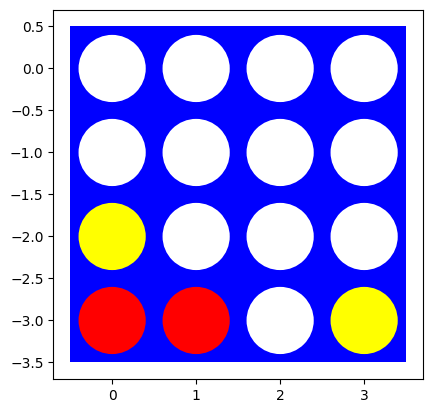

Number of nodes searched: 19054


{'move': 0, 'value': 1}

CPU times: user 286 ms, sys: 2.69 ms, total: 288 ms
Wall time: 290 ms

M2 thắng bằng nước Mean - nước đi mong đợi: (2, t)


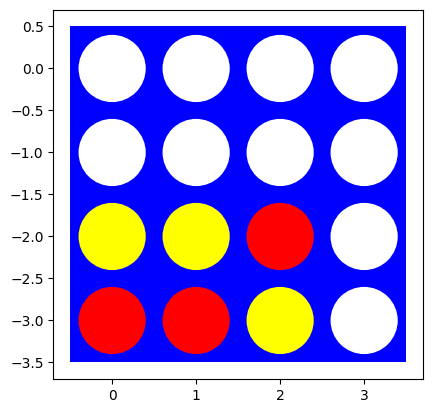

Number of nodes searched: 3543


{'move': (2, 0), 'value': 1}

CPU times: user 52.5 ms, sys: 582 μs, total: 53.1 ms
Wall time: 53 ms

M3 phải chặn - nước đi mong đợi: 2 hoặc (1, 0)


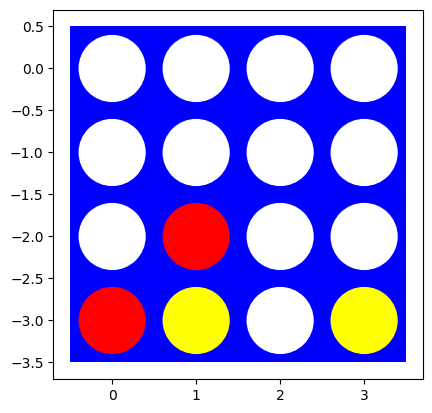

Number of nodes searched: 34936


{'move': 2, 'value': 1}

CPU times: user 517 ms, sys: 4.15 ms, total: 521 ms
Wall time: 527 ms

M4 thắng trước khi chặn - nước đi mong đợi: 0


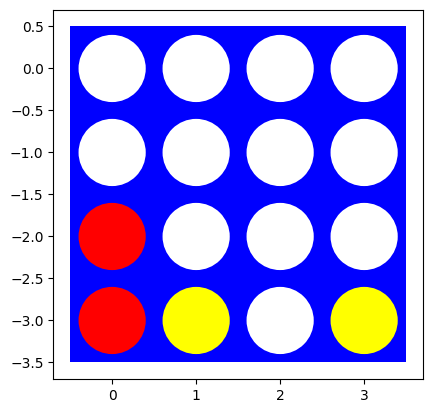

Number of nodes searched: 64155


{'move': 0, 'value': 1}

CPU times: user 935 ms, sys: 6.17 ms, total: 941 ms
Wall time: 941 ms

M5 phòng thủ nước Mean - nước đi mong đợi: (1, 2)


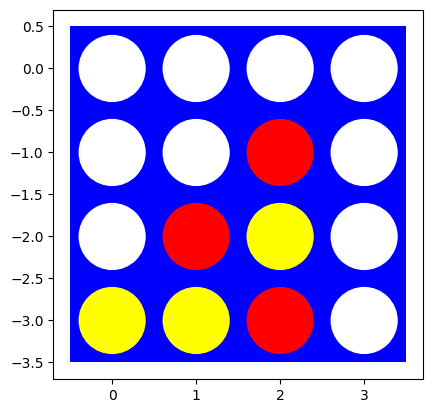

Number of nodes searched: 19743


{'move': (1, 2), 'value': 1}

CPU times: user 290 ms, sys: 2.45 ms, total: 293 ms
Wall time: 293 ms

M6 bàn rỗng - nước đi mong đợi: -


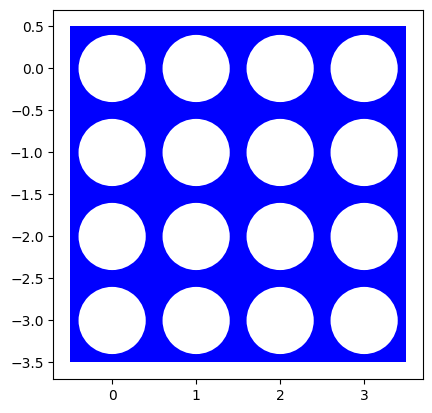

Number of nodes searched: 2965641


{'move': 0, 'value': 1}

CPU times: user 43.1 s, sys: 239 ms, total: 43.3 s
Wall time: 44.1 s



In [12]:
def make_board(pattern, shape = (4, 4)):
    """Đặt mẫu (các hàng từ trên xuống) vào góc dưới bên trái của bàn rỗng."""
    board = empty_board(shape)
    pattern = np.array(pattern)
    board[shape[0] - pattern.shape[0]:, :pattern.shape[1]] = pattern
    return board

# Bàn nhỏ 4x4 với luật nối 3 (CONNECT = 3). Đỏ (1) luôn là người đi tiếp.
TEST_BOARDS = {
    "M1 thắng ngay (thả quân)":  ([[ 0,  0, 0,  0],
                                   [ 0,  0, 0,  0],
                                   [-1,  0, 0,  0],
                                   [ 1,  1, 0, -1]], "2"),
    "M2 thắng bằng nước Mean":   ([[ 0,  0,  0, 0],
                                   [ 0,  0,  0, 0],
                                   [-1, -1,  1, 0],
                                   [ 1,  1, -1, 0]], "(2, t)"),
    "M3 phải chặn":              ([[ 0,  0, 0,  0],
                                   [ 0,  0, 0,  0],
                                   [ 0,  1, 0,  0],
                                   [ 1, -1, 0, -1]], "2 hoặc (1, 0)"),
    "M4 thắng trước khi chặn":   ([[ 0,  0, 0,  0],
                                   [ 0,  0, 0,  0],
                                   [ 1,  0, 0,  0],
                                   [ 1, -1, 0, -1]], "0"),
    "M5 phòng thủ nước Mean":    ([[ 0,  0,  0, 0],
                                   [ 0,  0,  1, 0],
                                   [ 0,  1, -1, 0],
                                   [-1, -1,  1, 0]], "(1, 2)"),
    "M6 bàn rỗng":               ([[0, 0, 0, 0]], "-"),
}

CONNECT = 3
DEBUG = 1
for name, (pattern, expected) in TEST_BOARDS.items():
    board = make_board(pattern)
    print(f"{name} - nước đi mong đợi: {expected}")
    visualize(board)
    %time display(alpha_beta_search(board, player = 1))
    print()

Ý nghĩa các bàn kiểm thử (bàn 4×4, nối 3; cột đánh số 0–3; nước Mean ghi `(f, t)`):

* **M1:** Đỏ có 2 quân ở đáy cột 0–1, thả vào cột 2 là thắng ngay.
* **M2:** không nước thả quân nào thắng ngay. Nhưng nếu Đỏ lấy quân Vàng ở đáy cột 2 (`(2, t)`), quân Đỏ phía trên rơi xuống
  và hàng đáy thành Đỏ–Đỏ–Đỏ: **thắng bằng nước Mean**.
* **M3:** Vàng dọa thả vào cột 2 để có Vàng–Vàng–Vàng ở hàng đáy. Đỏ có hai cách chặn: thả vào cột 2,
  hoặc đi nước Mean `(1, 0)` lấy quân Vàng ở đáy cột 1 (quân Đỏ phía trên rơi xuống thay chỗ).
* **M4:** giống M3 nhưng Đỏ có 2 quân dọc ở cột 0: thắng ngay ở cột 0 tốt hơn là chặn.
* **M5:** Vàng dọa đi nước Mean lấy quân Đỏ ở đáy cột 2: quân Vàng phía trên rơi xuống và hàng đáy thành Vàng–Vàng–Vàng.
  Thả quân không chặn được; chỉ có nước Mean `(1, 2)` (lấy quân Vàng ở đáy cột 1) vừa phá thế của Vàng vừa giữ thế thắng cho Đỏ.
* **M6:** bàn rỗng.

**Nhận xét:** * Agent tìm được **nước thắng hoặc giữ thắng ở cả 6 bàn**, tất cả đều có giá trị `1`.
  * **M2:** thắng bằng nước Mean `(2, 0)`.
  * **M5:** chọn đúng nước Mean phòng thủ duy nhất `(1, 2)`. Thả quân không cứu được ở bàn này.
* **M1:** agent chọn cột 0 chứ không phải cột 2 (thắng ngay). Đây không phải lỗi: từ cột 0, Đỏ vẫn chắc thắng ở các nước sau (giá trị vẫn là 1).
  Minimax không phân biệt thắng sớm hay thắng muộn và giữ nước đầu tiên có giá trị lớn nhất.
  Muốn ưu tiên thắng nhanh thì có thể trừ nhẹ utility theo độ sâu, hoặc dùng threat ordering (bảng dưới: threat chọn cột 2).
* **M3:** chặn ở cột 2, và hóa ra sau đó Đỏ còn thắng được (giá trị 1).
* **M6 bàn rỗng:** Đỏ đi trước **chắc thắng** trên bàn 4×4 nối 3, nhưng phải duyệt **2.965.641 nút (44 giây)**.
  Cùng bàn 4×4 này, Connect 4 thường (nối 4) chỉ cần 62.889 nút.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [13]:
DEBUG = 0

def timed_search(board, player = 1, limit = None, **args):
    """Chạy alpha_beta_search, trả về (kết quả, số nút, thời gian). Kết quả None nếu vượt quá limit giây."""
    global TIME_LIMIT
    TIME_LIMIT = limit
    start = time.perf_counter()
    try:
        res = alpha_beta_search(board, player = player, **args)
    except TimeoutError:
        res = None
    TIME_LIMIT = None
    return res, COUNT, time.perf_counter() - start

print("Nước đi đầu tiên trên bàn rỗng, tăng dần kích thước (giới hạn 60 giây):\n")
print(f"{'Bàn':>5} | {'nối':>3} | {'Nước đi':>8} | {'Giá trị':>9} | {'Số nút':>11} | {'Thời gian (s)':>13}")
for shape, k in [((4, 4), 3), ((4, 5), 3), ((4, 6), 3), ((4, 4), 4), ((6, 7), 4)]:
    CONNECT = k
    res, nodes, t = timed_search(empty_board(shape), limit = 60)
    move  = str(res["move"]) if res else "-"
    value = res["value"] if res else "chưa xong"
    print(f"{shape[0]}x{shape[1]:<3} | {k:>3} | {move:>8} | {value:>9} | {nodes:>11,} | {t:>13.2f}")
CONNECT = 3

Nước đi đầu tiên trên bàn rỗng, tăng dần kích thước (giới hạn 60 giây):

  Bàn | nối |  Nước đi |   Giá trị |      Số nút | Thời gian (s)


4x4   |   3 |        0 |         1 |   2,965,641 |         43.66


4x5   |   3 |        - | chưa xong |   3,575,227 |         60.00


4x6   |   3 |        - | chưa xong |   3,597,677 |         60.00


4x4   |   4 |        - | chưa xong |   3,684,170 |         60.00


6x7   |   4 |        - | chưa xong |   3,362,689 |         60.00


**Nhận xét:** * Bàn 4×4 nối 3 rỗng: 2.965.641 nút, **43,7 giây**.
* Thêm 1 cột (4×5, 4×6 nối 3): **không xong sau 60 giây**.
* Bàn 4×4 **nối 4** (luật Connect 4 chuẩn trên bàn nhỏ nhất): **không xong sau 60 giây** (3,7 triệu nút). Connect 4 thường chỉ mất 0,55 giây cho bàn này (Bài 8).
  Lý do: nối 4 trên bàn 4×4 khó xảy ra, nên ván kéo dài, và nước Mean làm cây rẽ nhánh rất nhiều.
* Bàn 6×7 thì không có hy vọng. Tốc độ vẫn khoảng 60.000 nút/giây, nhưng số nút tăng nhanh hơn nhiều so với Connect 4 thường.

### Move ordering

Starting the search with better moves will increase the efficiency of alpha-beta pruning. Describe and implement a simple move ordering strategy. Make a table that shows how the ordering strategies influence the time it takes to make a move?

Hai chiến lược sắp thứ tự, so với thứ tự mặc định (thả quân cột 0 → cột cuối, rồi các nước Mean):

1. **center:** thả quân vào các cột gần giữa trước, các nước Mean để sau.
2. **threat:** nước thắng ngay (kể cả nước Mean thắng ngay) trước, rồi các nước thả quân chặn nước thả quân thắng ngay của đối thủ, rồi theo center.

In [14]:
def center_order(board, player):
    """Thả quân vào các cột gần giữa trước, sau đó tới các nước Mean."""
    c = (board.shape[1] - 1) / 2
    acts = actions(board, player)
    drops = sorted([a for a in acts if not isinstance(a, tuple)], key = lambda a: abs(a - c))
    means = [a for a in acts if isinstance(a, tuple)]
    return drops + means

def threat_order(board, player):
    """Nước thắng ngay (kể cả nước Mean) trước, rồi các nước thả quân chặn nước thả quân thắng ngay của đối thủ,
    rồi theo thứ tự center."""
    acts = center_order(board, player)
    win   = [a for a in acts if check_board(result(board, player, a)) == player]
    block = [a for a in acts if not isinstance(a, tuple) and a not in win
             and check_board(result(board, -player, a)) == -player]
    rest  = [a for a in acts if a not in win and a not in block]
    return win + block + rest

In [15]:
DEBUG = 0
CONNECT = 3
ORDERS = {"none": None, "center": center_order, "threat": threat_order}

print(f"{'Bàn 4x4 (nối 3)':<28} | " + " | ".join(f"{o + ': nút':>14} {'(s)':>6}" for o in ORDERS))
total = {o: [0, 0.0] for o in ORDERS}
for name, (pattern, expected) in TEST_BOARDS.items():
    board = make_board(pattern)
    row = []
    for o, f in ORDERS.items():
        res, nodes, t = timed_search(board, 1, limit = 60, order = f)
        total[o][0] += nodes; total[o][1] += t
        row.append(f"{nodes:>14,} {t:>6.2f}" + ("" if res else "*"))
    print(f"{name:<28} | " + " | ".join(row))
print(f"{'TỔNG':<28} | " + " | ".join(f"{total[o][0]:>14,} {total[o][1]:>6.1f}" for o in ORDERS))
print("* = dừng vì quá 60 giây")

Bàn 4x4 (nối 3)              |      none: nút    (s) |    center: nút    (s) |    threat: nút    (s)


M1 thắng ngay (thả quân)     |         19,054   0.29 |         12,584   0.20 |          2,931   0.30
M2 thắng bằng nước Mean      |          3,543   0.05 |          3,928   0.06 |             34   0.00


M3 phải chặn                 |         34,936   0.51 |         25,425   0.39 |          1,261   0.12


M4 thắng trước khi chặn      |         64,155   0.94 |         30,028   0.47 |          1,916   0.16


M5 phòng thủ nước Mean       |         19,743   0.29 |         16,717   0.26 |            717   0.05


M6 bàn rỗng                  |      2,965,641  42.97 |        548,211   8.32 |         40,426   3.40
TỔNG                         |      3,107,072   45.0 |        636,893    9.7 |         47,285    4.0
* = dừng vì quá 60 giây


**Nhận xét:** * Move ordering **quan trọng hơn nhiều** so với Connect 4.
  * Tổng 6 bàn: none 3.107.072 nút (45,0 s), center 636.893 nút (9,7 s), **threat 47.285 nút (4,0 s)**. Threat giảm số nút **khoảng 66 lần**, thời gian khoảng 11 lần.
  * Ở Bài 8, threat chỉ giảm số nút khoảng 2,2 lần.
* **Bàn rỗng** giảm từ 2.965.641 xuống 40.426 nút (43 giây xuống 3,4 giây). **M2** (thắng bằng nước Mean) giảm từ 3.543 xuống chỉ **34 nút**.
* Lý do:
  * Hệ số rẽ nhánh lớn (tới vài chục nước), nên mỗi lần cắt tỉa sớm loại bỏ được rất nhiều cây con.
  * Với luật nối 3, gần như bàn nào cũng có nước thắng ngay hoặc nước phải chặn. Threat ordering thử chúng trước, nên `alpha`/`beta` đạt giá trị cuối cùng ngay từ nước đầu.
* **Center** cũng giúp khoảng 5 lần, vì nó đưa các nước thả quân lên trước các nước Mean. Phần lớn nước Mean (ví dụ đặt quân về chỗ cũ) là nước yếu.

### The first few moves

Start with an empty board. This is the worst case scenario for minimax search with alpha-beta pruning since it needs solve all possible games that can be played (minus some pruning) before making the decision. What can you do? 

In [16]:
CONNECT = 3
DEBUG = 1
print("Bàn 4x4 rỗng (nối 3), tìm kiếm đầy đủ với threat ordering:")
%time display(alpha_beta_search(empty_board((4, 4)), player = 1, order = threat_order))

DEBUG = 0
ab_agent = SearchAgent(alpha_beta_search, name = "Alpha-Beta (4x4, nối 3)", order = threat_order)
%time print("Agent lần 1:", ab_agent.act(empty_board((4, 4)), 1))
%time print("Agent lần 2 (lấy từ memory):", ab_agent.act(empty_board((4, 4)), 1))

Bàn 4x4 rỗng (nối 3), tìm kiếm đầy đủ với threat ordering:


Number of nodes searched: 40426


{'move': 1, 'value': 1}

CPU times: user 3.39 s, sys: 6.82 ms, total: 3.4 s
Wall time: 3.39 s


Agent lần 1: 1
CPU times: user 3.38 s, sys: 6.94 ms, total: 3.39 s
Wall time: 3.39 s
Agent lần 2 (lấy từ memory): 1
CPU times: user 42 μs, sys: 13 μs, total: 55 μs
Wall time: 54.8 μs


**Nhận xét:** * Với threat ordering, nước đầu trên bàn 4×4 rỗng (nối 3) cần 40.426 nút, khoảng **3,4 giây**. Agent chọn cột 1, và biết chắc thắng (giá trị 1).
* Memory của agent: lần 2 chỉ mất **55 µs**.

Những việc có thể làm với các nước đầu tiên:

* **Lưu kết quả / sách khai cuộc:** bàn rỗng luôn giống nhau nên chỉ tính một lần (memory trong `SearchAgent`: lần 2 gần như tức thì).
  Có thể tính trước nước đi cho vài nước đầu và lưu thành "opening book".
* **Cắt độ sâu + heuristic** (Task 4): ở đầu ván chưa cần tính tới cuối, chỉ cần một nước đi hợp lý.
* **Bảng chuyển vị:** với Mean Connect 4 càng quan trọng hơn, vì nước Mean làm cùng một bàn cờ xuất hiện lại qua rất nhiều đường đi khác nhau.
* **Đối xứng trái–phải** để chỉ xét nửa số nước ở bàn rỗng, và **move ordering** (threat) như bảng trên.

### Playtime

Let the Minimax Search agent play a random agent on a small board. Analyze wins, losses and draws.

In [17]:
CONNECT = 3
DEBUG = 0
SUMMARY = {("Random (6x7)", "đi trước"): (1000, random_results[1], random_results['d'], random_results[-1], None)}

print("Alpha-Beta (Đỏ, đi trước) vs. random, bàn 4x4 nối 3:")
ab_agent.reset_stats()
%time res, st = play(ab_agent.act, random_player, N = 100, shape = (4, 4), return_stats = True)
display(res)
SUMMARY[(ab_agent.name, "đi trước")] = (100, res[1], res['d'], res[-1], ab_agent.avg_time())
print(f"TB {ab_agent.avg_time() * 1000:.1f} ms/nước | độ dài ván TB {st['avg_length']:.1f} | tỷ lệ nước Mean (cả 2 bên) {st['mean_move_share']:.1%}")

print()
print("random (Đỏ, đi trước) vs. Alpha-Beta, bàn 4x4 nối 3:")
ab_agent.reset_stats()
%time res, st = play(random_player, ab_agent.act, N = 100, shape = (4, 4), return_stats = True)
display(res)
SUMMARY[(ab_agent.name, "đi sau")] = (100, res[-1], res['d'], res[1], ab_agent.avg_time())
print(f"TB {ab_agent.avg_time() * 1000:.1f} ms/nước | độ dài ván TB {st['avg_length']:.1f} | tỷ lệ nước Mean (cả 2 bên) {st['mean_move_share']:.1%}")

Alpha-Beta (Đỏ, đi trước) vs. random, bàn 4x4 nối 3:


CPU times: user 1min 37s, sys: 460 ms, total: 1min 37s
Wall time: 1min 38s


{1: 100, -1: 0, 'd': 0}

TB 304.9 ms/nước | độ dài ván TB 5.5 | tỷ lệ nước Mean (cả 2 bên) 26.1%

random (Đỏ, đi trước) vs. Alpha-Beta, bàn 4x4 nối 3:


CPU times: user 1min 36s, sys: 624 ms, total: 1min 37s
Wall time: 1min 38s


{1: 1, -1: 97, 'd': 2}

TB 264.5 ms/nước | độ dài ván TB 7.5 | tỷ lệ nước Mean (cả 2 bên) 18.8%


**Nhận xét:** * **Alpha-Beta đi trước thắng 100/100 ván.** Bàn 4×4 nối 3 là thế thắng cho người đi trước, và agent luôn đi theo đường thắng.
* **Alpha-Beta đi sau:** thắng 97, hòa 2, **thua 1**. Người đi trước có đường thắng chắc chắn, nên thỉnh thoảng Random đi trước tình cờ đi đúng đường đó và agent không cứu được.
* Ván rất ngắn (5,5 và 7,5 nước trung bình) vì chỉ cần nối 3.
* Nước Mean chiếm 19–26% số nước (tính cả hai bên). Agent dùng nước Mean khi cần, như ở bàn M5.
* Thời gian trung bình **265–305 ms/nước**, chậm hơn khoảng 20 lần so với Connect 4 4×4 ở Bài 8 (10–15 ms/nước), dù đã có memory và threat ordering.

## Task 4: Heuristic Alpha-Beta Tree Search [3 points] 

### Heuristic evaluation function

Define and implement a heuristic evaluation function.

In [18]:
def eval_fun(board, player = 1):
    """Heuristic giống bài Connect 4: các đoạn CONNECT ô chỉ có quân một bên
    (CONNECT-1 quân: 5 điểm, CONNECT-2 quân: 2 điểm), cộng 3 điểm cho mỗi quân ở cột giữa.
    Điểm thô chia 50 rồi nén bằng x / (1 + |x|) để luôn nằm trong (-1, 1). Trả về (giá trị, terminal?)."""
    u = utility(board, player)
    if u is not None: return u, True

    w = board.ravel()[get_windows(board.shape)]
    mine, theirs = np.sum(w == player, axis = 1), np.sum(w == -player, axis = 1)
    score  = 5 * np.sum((mine == CONNECT - 1) & (theirs == 0)) + 2 * np.sum((mine == CONNECT - 2) & (theirs == 0))
    score -= 5 * np.sum((theirs == CONNECT - 1) & (mine == 0)) + 2 * np.sum((theirs == CONNECT - 2) & (mine == 0))
    center = board[:, board.shape[1] // 2]
    score += 3 * (np.sum(center == player) - np.sum(center == -player))

    x = score / 50
    return x / (1 + abs(x)), False

def eval_fun_mean(board, player = 1):
    """Heuristic có tính tới luật Mean:
    * quân của mình nằm ở hàng đáy có thể bị đối thủ lấy đi: trừ 2 điểm mỗi quân;
    * quân của đối thủ ở hàng đáy là "tài nguyên" để mình đi nước Mean: cộng 2 điểm mỗi quân.
    Phần còn lại giống eval_fun."""
    u = utility(board, player)
    if u is not None: return u, True

    w = board.ravel()[get_windows(board.shape)]
    mine, theirs = np.sum(w == player, axis = 1), np.sum(w == -player, axis = 1)
    score  = 5 * np.sum((mine == CONNECT - 1) & (theirs == 0)) + 2 * np.sum((mine == CONNECT - 2) & (theirs == 0))
    score -= 5 * np.sum((theirs == CONNECT - 1) & (mine == 0)) + 2 * np.sum((theirs == CONNECT - 2) & (mine == 0))
    center = board[:, board.shape[1] // 2]
    score += 3 * (np.sum(center == player) - np.sum(center == -player))
    score += 2 * (np.sum(board[-1] == -player) - np.sum(board[-1] == player))

    x = score / 50
    return x / (1 + abs(x)), False

In [19]:
CONNECT = 4
board = np.array([[ 0,  0,  0,  0,  0,  0,  0],
                  [ 0,  0,  0,  0,  0,  0,  0],
                  [ 0,  0,  0,  0,  0,  0,  0],
                  [ 0,  0,  0,  1,  0,  0,  0],
                  [ 0,  0,  0,  1,  0,  0,  0],
                  [ 0, -1, -1,  1, -1,  0,  0]])
print("Bàn ví dụ của đề:")
print(f"  eval_fun     : Đỏ {eval_fun(board, 1)[0]:+.3f} | Vàng {eval_fun(board, -1)[0]:+.3f}")
print(f"  eval_fun_mean: Đỏ {eval_fun_mean(board, 1)[0]:+.3f} | Vàng {eval_fun_mean(board, -1)[0]:+.3f}")

# kiểm tra khoảng giá trị trên các bàn gặp trong 300 ván Random vs. Random
vals = []
for i in range(300):
    b, p = empty_board(), 1
    for m in range(np.random.randint(5, 40)):
        b = result(b, p, random_player(b, p)); p = -p
        if terminal(b): break
    if not terminal(b): vals += [eval_fun(b, 1)[0], eval_fun_mean(b, 1)[0]]
print(f"\nTrên {len(vals) // 2} bàn ngẫu nhiên chưa kết thúc: min = {min(vals):.3f}, max = {max(vals):.3f}")

Bàn ví dụ của đề:
  eval_fun     : Đỏ +0.242 | Vàng -0.242
  eval_fun_mean: Đỏ +0.286 | Vàng -0.286

Trên 154 bàn ngẫu nhiên chưa kết thúc: min = -0.457, max = 0.438


**Nhận xét:** * Ở bàn ví dụ của đề, `eval_fun` cho Đỏ **+0,242**, còn `eval_fun_mean` cho **+0,286**.
  Đỏ chỉ có 1 quân ở hàng đáy (dễ bị lấy), còn Vàng có 3 quân ở hàng đáy mà Đỏ có thể lấy. Vì vậy hàm có tính luật Mean đánh giá Đỏ tốt hơn.
* Cả hai hàm đều đối xứng (giá trị cho Vàng là số đối) và nằm trong **[−0,457; 0,438]** trên 154 bàn ngẫu nhiên, luôn trong khoảng (−1, 1).

### Cutting off search 

Modify your Minimax Search with Alpha-Beta Pruning to cut off search at a specified depth and use the heuristic evaluation function. Experiment with different cutoff values.

In [20]:
# global variables
DEBUG = 1
COUNT = 0

def heuristic_alpha_beta_search(board, player = 1, cutoff = 2, order = threat_order, eval_fun = eval_fun):
    """Alpha-beta cắt ở độ sâu cutoff, dùng eval_fun ở nút bị cắt. Trạng thái lặp trên đường đi = hòa."""
    global DEBUG, COUNT
    COUNT = 0
    value, move = max_value_h(board, player, -math.inf, +math.inf, 0, cutoff, order, eval_fun, set())
    if DEBUG >= 1: print(f"Number of nodes searched (cutoff = {cutoff}): {COUNT}")
    return {"move": move, "value": value}

def max_value_h(state, player, alpha, beta, depth, cutoff, order, eval_fun, path):
    global DEBUG, COUNT
    COUNT += 1

    v, terminal = eval_fun(state, player)
    if (cutoff is not None and depth >= cutoff) or terminal:
        if DEBUG >= 2: print(f"stopped at {depth}: {state.tolist()} term: {terminal} eval: {v} [{alpha}, {beta}]")
        return v, None

    key = (state.tobytes(), player)
    if key in path: return 0, None
    path.add(key)

    v, move = -math.inf, None
    for a in order(state, player):
        v2, a2 = min_value_h(result(state, player, a), player, alpha, beta, depth + 1, cutoff, order, eval_fun, path)
        if v2 > v:
            v, move = v2, a
            alpha = max(alpha, v)
        if v >= beta: break

    path.discard(key)
    return v, move

def min_value_h(state, player, alpha, beta, depth, cutoff, order, eval_fun, path):
    global DEBUG, COUNT
    COUNT += 1

    v, terminal = eval_fun(state, player)
    if (cutoff is not None and depth >= cutoff) or terminal:
        if DEBUG >= 2: print(f"stopped at {depth}: {state.tolist()} term: {terminal} eval: {v} [{alpha}, {beta}]")
        return v, None

    key = (state.tobytes(), -player)
    if key in path: return 0, None
    path.add(key)

    v, move = +math.inf, None
    for a in order(state, -player):
        v2, a2 = max_value_h(result(state, -player, a), player, alpha, beta, depth + 1, cutoff, order, eval_fun, path)
        if v2 < v:
            v, move = v2, a
            beta = min(beta, v)
        if v <= alpha: break

    path.discard(key)
    return v, move

In [21]:
# Thử các độ sâu cắt trên bàn M5 (phòng thủ nước Mean), 4x4 nối 3, so với tìm kiếm đầy đủ
CONNECT = 3
DEBUG = 1
board = make_board(TEST_BOARDS["M5 phòng thủ nước Mean"][0])
for cutoff in [1, 2, 3, 4, None]:
    %time display(heuristic_alpha_beta_search(board, player = 1, cutoff = cutoff))
    print()

Number of nodes searched (cutoff = 1): 13


{'move': 1, 'value': np.float64(0.3333333333333333)}

CPU times: user 1.86 ms, sys: 435 μs, total: 2.3 ms
Wall time: 3.33 ms

Number of nodes searched (cutoff = 2): 40


{'move': 0, 'value': 0}

CPU times: user 4.65 ms, sys: 188 μs, total: 4.84 ms
Wall time: 4.84 ms

Number of nodes searched (cutoff = 3): 101


{'move': (0, 2), 'value': np.float64(0.24242424242424243)}

CPU times: user 10.6 ms, sys: 197 μs, total: 10.8 ms
Wall time: 10.8 ms

Number of nodes searched (cutoff = 4): 128


{'move': 0, 'value': 0}

CPU times: user 16.1 ms, sys: 192 μs, total: 16.3 ms
Wall time: 16.3 ms

Number of nodes searched (cutoff = None): 717


{'move': (1, 2), 'value': 1}

CPU times: user 66.1 ms, sys: 424 μs, total: 66.5 ms
Wall time: 66.5 ms



**Nhận xét:** * Trên M5 (phòng thủ nước Mean), **chỉ tìm kiếm đầy đủ** (717 nút) tìm ra nước thắng `(1, 2)`.
  * cutoff 1 chọn cột 1;
  * cutoff 2 và 4 chọn cột 0 (giá trị 0: nước này chỉ giữ được hòa);
  * cutoff 3 chọn `(0, 2)`.
* Nước thắng cần nhìn qua chuỗi: Đỏ lấy quân → Vàng mất thế → Đỏ thắng sau vài nước. Heuristic với độ sâu nhỏ chưa thấy kết thúc nên chọn nước "an toàn".
* Số nút tăng nhanh theo độ sâu (13 → 40 → 101 → 128 → 717), nhưng tất cả vẫn dưới 0,07 giây trên bàn nhỏ này.

Experiment with the same manually created boards as above to check if the agent spots winning opportunities.

In [22]:
CONNECT = 3
DEBUG = 0

def run_heuristic(board, player, cutoff, **args):
    start = time.perf_counter()
    res = heuristic_alpha_beta_search(board, player = player, cutoff = cutoff, **args)
    return res, COUNT, time.perf_counter() - start

print(f"{'Bàn 4x4 (nối 3)':<26} | {'mong đợi':>13} | " + " | ".join(f"{'cutoff=' + str(c):>26}" for c in [2, 4, None]))
for name, (pattern, expected) in TEST_BOARDS.items():
    board = make_board(pattern)
    row = []
    for cutoff in [2, 4, None]:
        res, nodes, t = run_heuristic(board, 1, cutoff)
        row.append(f"{str(res['move']):>7} {float(res['value']):>6.3f} {nodes:>7,} {t:>4.2f}")
    print(f"{name:<26} | {expected:>13} | " + " | ".join(f"{r:>26}" for r in row))
print("(mỗi ô: nước đi, giá trị, số nút, giây)")

Bàn 4x4 (nối 3)            |      mong đợi |                   cutoff=2 |                   cutoff=4 |                cutoff=None


M1 thắng ngay (thả quân)   |             2 |       2  1.000      16 0.00 |       2  1.000     135 0.02 |       2  1.000   2,931 0.36
M2 thắng bằng nước Mean    |        (2, t) |  (2, 0)  1.000      13 0.00 |  (2, 0)  1.000      25 0.00 |  (2, 0)  1.000      34 0.00
M3 phải chặn               | 2 hoặc (1, 0) |       2  0.000      36 0.00 |       2  0.107     202 0.03 |       2  1.000   1,261 0.14


M4 thắng trước khi chặn    |             0 |       0  1.000      24 0.00 |       0  1.000      88 0.01 |       0  1.000   1,916 0.19
M5 phòng thủ nước Mean     |        (1, 2) |       0  0.000      40 0.00 |       0  0.000     128 0.02 |  (1, 2)  1.000     717 0.07


M6 bàn rỗng                |             - |       0 -0.091      25 0.00 |       2  0.000     301 0.03 |       1  1.000  40,426 4.10
(mỗi ô: nước đi, giá trị, số nút, giây)


**Nhận xét:** * Heuristic với cutoff 2 và 4 **thấy được các nước thắng ngay** (M1, M2, M4), kể cả **thắng bằng nước Mean** ở M2 (giá trị 1,000 chỉ sau 13–25 nút).
* **M3:** heuristic chặn đúng (cột 2) nhưng chưa thấy đây là nước thắng. Tìm kiếm đầy đủ mới cho giá trị 1.
* **M5:** heuristic **không tìm ra** nước phòng thủ `(1, 2)` và chọn cột 0 (chỉ hòa).
  Đây là điểm yếu riêng của Mean Connect 4: mối đe dọa đến từ nước Mean của đối thủ (quân rơi xuống), mà hàm đánh giá tĩnh chỉ nhìn các đoạn quân hiện có nên không thấy.
* Tìm kiếm đầy đủ có threat ordering rẻ trên các bàn này (34–2.931 nút), chỉ bàn rỗng mới cần 40.426 nút.

How long does it take to make a move? Start with a smaller board with 4 columns and make the board larger by adding columns.

In [23]:
CONNECT = 4
DEBUG = 0

def random_board(shape, moves):
    """Cho hai random_player đi `moves` nước (ván chưa kết thúc). Trả về (bàn cờ, người đi tiếp)."""
    while True:
        board, player = empty_board(shape), 1
        for i in range(moves):
            board = result(board, player, random_player(board, player))
            player = -player
            if terminal(board): break
        if not terminal(board): return board, player

print("Heuristic alpha-beta (nối 4): nước đầu tiên (bàn rỗng) và nước giữa ván (sau 12 nước ngẫu nhiên, TB 5 bàn):\n")
print(f"{'Bàn':>5} | {'cutoff':>6} | {'rỗng: nút':>10} {'s':>7} | {'giữa ván: số nước':>17} {'nút TB':>9} {'s TB':>7}")
for shape in [(4, 4), (4, 5), (4, 6), (4, 7), (5, 7), (6, 7)]:
    mids = [random_board(shape, 12) for i in range(5)]
    for cutoff in [2, 3, 4]:
        res, n0, t0 = run_heuristic(empty_board(shape), 1, cutoff)
        stats = [run_heuristic(b, p, cutoff)[1:] for b, p in mids]
        n_acts = np.mean([len(actions(b, p)) for b, p in mids])
        print(f"{shape[0]}x{shape[1]:<3} | {cutoff:>6} | {n0:>10,} {t0:>7.3f} | {n_acts:>17.1f} "
              f"{np.mean([s[0] for s in stats]):>9,.0f} {np.mean([s[1] for s in stats]):>7.3f}")

Heuristic alpha-beta (nối 4): nước đầu tiên (bàn rỗng) và nước giữa ván (sau 12 nước ngẫu nhiên, TB 5 bàn):

  Bàn | cutoff |  rỗng: nút       s | giữa ván: số nước    nút TB    s TB
4x4   |      2 |         23   0.002 |               8.4        36   0.004
4x4   |      3 |         78   0.007 |               8.4       135   0.013


4x4   |      4 |        340   0.031 |               8.4       372   0.044
4x5   |      2 |         20   0.002 |              10.8        32   0.005
4x5   |      3 |         74   0.007 |              10.8       213   0.019


4x5   |      4 |        240   0.029 |              10.8       486   0.075
4x6   |      2 |         35   0.004 |              11.4        40   0.007
4x6   |      3 |        150   0.015 |              11.4       220   0.024


4x6   |      4 |        790   0.083 |              11.4       992   0.142
4x7   |      2 |         28   0.004 |              16.6        61   0.011


4x7   |      3 |        138   0.015 |              16.6       580   0.059


4x7   |      4 |        464   0.068 |              16.6     1,483   0.318
5x7   |      2 |         28   0.004 |              15.4        56   0.010


5x7   |      3 |        138   0.015 |              15.4       381   0.040


5x7   |      4 |        462   0.070 |              15.4     1,237   0.233
6x7   |      2 |         28   0.004 |              15.4        70   0.011


6x7   |      3 |        138   0.016 |              15.4       379   0.042


6x7   |      4 |        462   0.071 |              15.4       910   0.229


**Nhận xét:** * **Bàn rỗng rẻ** vì chưa có quân ở hàng đáy, tức chưa có nước Mean. Ví dụ 6×7 cutoff 4 cần 462 nút, 0,07 giây.
* **Giữa ván đắt hơn nhiều** vì số nước đi tăng (15,4 nước trên bàn 6×7 sau 12 nước, so với tối đa 7 ở Connect 4).
  Bàn 6×7 cutoff 4 giữa ván cần 910 nút, **0,23 giây**. Bàn 4×7 là chậm nhất: 1.483 nút, 0,32 giây.
* Mỗi bậc cutoff thêm vào làm số nút giữa ván tăng khoảng 2,4–5,4 lần (6×7: 70 → 379 → 910).
* So với Bài 8, cùng cutoff 4 trên bàn 6×7 giữa ván, Mean chậm hơn khoảng 16 lần (0,229 s so với 0,014 s).
  Do đó với Mean Connect 4, cutoff 4 là mức hợp lý trên bàn chuẩn; Connect 4 thường dùng được cutoff 6 hoặc sâu hơn.

### Playtime

Let two heuristic search agents (different cutoff depth, different heuristic evaluation function) compete against each other on a reasonably sized board. Since there is no randomness, you only need to let them play once.

h2 (eval_fun) (Đỏ) vs. h4 (eval_fun_mean) (Vàng): {1: 0, -1: 0, 'd': 1} | 50 nước, nước Mean 32%


h4 (eval_fun_mean) (Đỏ) vs. h2 (eval_fun) (Vàng): {1: 1, -1: 0, 'd': 0} | 27 nước, nước Mean 33%


h2 (eval_fun_mean) (Đỏ) vs. h4 (eval_fun) (Vàng): {1: 0, -1: 0, 'd': 1} | 38 nước, nước Mean 5%


h4 (eval_fun) (Đỏ) vs. h2 (eval_fun_mean) (Vàng): {1: 1, -1: 0, 'd': 0} | 21 nước, nước Mean 29%


h4 (eval_fun) (Đỏ) vs. h4 (eval_fun_mean) (Vàng): {1: 1, -1: 0, 'd': 0} | 23 nước, nước Mean 30%


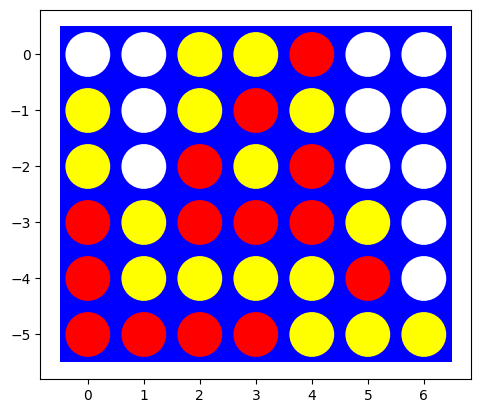

h4 (eval_fun_mean) (Đỏ) vs. h4 (eval_fun) (Vàng): {1: 0, -1: 0, 'd': 1} | 33 nước, nước Mean 9%


In [24]:
CONNECT = 4
DEBUG = 0
h2  = SearchAgent(heuristic_alpha_beta_search, name = "h2 (eval_fun)", cutoff = 2, eval_fun = eval_fun)
h2m = SearchAgent(heuristic_alpha_beta_search, name = "h2 (eval_fun_mean)", cutoff = 2, eval_fun = eval_fun_mean)
h4  = SearchAgent(heuristic_alpha_beta_search, name = "h4 (eval_fun)", cutoff = 4, eval_fun = eval_fun)
h4m = SearchAgent(heuristic_alpha_beta_search, name = "h4 (eval_fun_mean)", cutoff = 4, eval_fun = eval_fun_mean)

# Không có yếu tố ngẫu nhiên -> mỗi cặp đấu 1 ván cho mỗi bên đi trước, bàn 6x7 (1 = Đỏ thắng, -1 = Vàng thắng)
for a, b in [(h2, h4m), (h4m, h2), (h2m, h4), (h4, h2m), (h4, h4m), (h4m, h4)]:
    res, st = play(a.act, b.act, N = 1, return_stats = True, show_final_board = (a is h4m and b is h4))
    print(f"{a.name} (Đỏ) vs. {b.name} (Vàng): {res} | {st['avg_length']:.0f} nước, nước Mean {st['mean_move_share']:.0%}")

**Nhận xét:** Kết quả 6 ván trên bàn 6×7 (h2/h4 = cutoff 2/4; `eval_fun` hoặc `eval_fun_mean`):

| Đỏ (đi trước) | Vàng | Kết quả | Số nước | % nước Mean |
|---|---|---|---|---|
| h2 (eval_fun) | h4 (eval_fun_mean) | hòa | 50 | 32% |
| h4 (eval_fun_mean) | h2 (eval_fun) | Đỏ thắng | 27 | 33% |
| h2 (eval_fun_mean) | h4 (eval_fun) | hòa | 38 | 5% |
| h4 (eval_fun) | h2 (eval_fun_mean) | Đỏ thắng | 21 | 29% |
| h4 (eval_fun) | h4 (eval_fun_mean) | Đỏ thắng | 23 | 30% |
| h4 (eval_fun_mean) | h4 (eval_fun) | hòa | 33 | 9% |

* **Cutoff 4 mạnh hơn cutoff 2:** khi đi trước, h4 luôn thắng h2; khi đi sau, h4 vẫn giữ được hòa. Người đi sau không thắng ván nào.
* **`eval_fun_mean` không tốt hơn rõ rệt.** Giữa hai h4, bản dùng `eval_fun` thắng khi đi trước, còn bản dùng `eval_fun_mean` chỉ hòa khi đi trước.
  Phần thưởng/phạt cho quân ở hàng đáy có thể chưa đúng trọng số. Mỗi cặp chỉ có 1 ván nên chưa đủ để kết luận.
* Các agent dùng nước Mean **5–33%** số nước, ít hơn Random (56%). Chúng chỉ dùng nước Mean khi nó có lợi, không dùng bừa.

In [25]:
# Heuristic đấu random trên bàn 6x7 để so sánh với Connect 4 (Bài 8)
CONNECT = 4
DEBUG = 0
for agent in [h2, h4m]:
    for first in [True, False]:
        agent.reset_stats()
        start = time.perf_counter()
        res, st = (play(agent.act, random_player, return_stats = True) if first
                   else play(random_player, agent.act, return_stats = True))
        me = 1 if first else -1
        SUMMARY[(agent.name, "đi trước" if first else "đi sau")] = (100, res[me], res['d'], res[-me], agent.avg_time())
        print(f"{agent.name} {'(Đỏ)' if first else '(Vàng)'} vs. random: {res}, TB {agent.avg_time() * 1000:.1f} ms/nước, "
              f"ván dài TB {st['avg_length']:.1f} nước, tổng {time.perf_counter() - start:.1f} s")

h2 (eval_fun) (Đỏ) vs. random: {1: 100, -1: 0, 'd': 0}, TB 6.3 ms/nước, ván dài TB 10.1 nước, tổng 3.5 s


h2 (eval_fun) (Vàng) vs. random: {1: 0, -1: 100, 'd': 0}, TB 10.4 ms/nước, ván dài TB 13.0 nước, tổng 6.8 s


h4 (eval_fun_mean) (Đỏ) vs. random: {1: 100, -1: 0, 'd': 0}, TB 122.9 ms/nước, ván dài TB 9.9 nước, tổng 66.8 s


h4 (eval_fun_mean) (Vàng) vs. random: {1: 0, -1: 100, 'd': 0}, TB 384.4 ms/nước, ván dài TB 16.4 nước, tổng 315.2 s


**Nhận xét:** * Cả hai heuristic agent đều **thắng 100/100 ván** trước Random, dù đi trước hay đi sau, giống Connect 4.
* Thời gian khác nhau nhiều:
  * h2: 6–10 ms/nước.
  * h4 (`eval_fun_mean`): **123 ms/nước khi đi trước và 384 ms/nước khi đi sau**. Ván dài hơn, nhiều quân đáy hơn, nên nhiều nước Mean phải xét.
  * Ở Bài 8, h4 chỉ cần 7–13 ms/nước.

## Tournament task [+ 1 to 5 bonus point will be assigned separately]

Find another student and let your best agent play against the other student's best player. You are allowed to use any improvements you like as long as you code it yourself. We will set up a class tournament on Canvas. This tournament will continue after the submission deadline.

*Nhóm không tham gia phần tournament (không bắt buộc).*

## Graduate student advanced task: Pure Monte Carlo Search and Best First Move [1 point]

__Undergraduate students:__ This is a bonus task you can attempt if you like [+1 Bonus point].

### Pure Monte Carlo Search

Implement Pure Monte Carlo Search (see [tic-tac-toe-example](tictactoe_pure_monte_carlo_search.ipynb)) and investigate how this search performs on the test boards that you have used above. 

In [26]:
def playout(board, action, player = 1, max_moves = 200):
    """Chơi ngẫu nhiên tới hết ván (quá max_moves nước thì tính hòa), bắt đầu bằng action của player."""
    board = result(board, player, action)
    current_player = -player
    for i in range(max_moves):
        u = utility(board, player)
        if u is not None: return u
        board = result(board, current_player, random_player(board, current_player))
        current_player = -current_player
    return 0

def playouts(board, action, player = 1, N = 100):
    return [playout(board, action, player) for i in range(N)]

DEBUG = 1

def pmcs(board, N = 100, player = 1):
    """Pure Monte Carlo Search: chia đều N playout cho các nước đi, chọn nước có utility trung bình lớn nhất."""
    global DEBUG
    acts = actions(board, player)
    n = max(math.floor(N / len(acts)), 1)
    if DEBUG >= 1: print(f"{len(acts)} actions ({N} total playouts = {n} playouts per action)")
    ps = {a: np.mean(playouts(board, a, player, N = n)) for a in acts}
    action = max(ps, key = ps.get)
    if DEBUG >= 1: print(f"best: {action} (mean utility {ps[action]:.3f})")
    return action

In [27]:
# PMCS trên các bàn kiểm thử 4x4 (nối 3). Mỗi cấu hình chạy 5 lần để xem nước đi có ổn định không.
CONNECT = 3
DEBUG = 0
print(f"{'Bàn 4x4 (nối 3)':<26} | {'mong đợi':>13} | {'N':>5} | {'nước đi qua 5 lần':<45} | {'s/lần':>6}")
for name, (pattern, expected) in TEST_BOARDS.items():
    board = make_board(pattern)
    for N in [100, 1000]:
        start = time.perf_counter()
        moves = [pmcs(board, N = N, player = 1) for i in range(5)]
        t = (time.perf_counter() - start) / 5
        print(f"{name:<26} | {expected:>13} | {N:>5} | {str(moves):<45} | {t:>6.3f}")

Bàn 4x4 (nối 3)            |      mong đợi |     N | nước đi qua 5 lần                             |  s/lần
M1 thắng ngay (thả quân)   |             2 |   100 | [0, 2, 2, 2, 2]                               |  0.014


M1 thắng ngay (thả quân)   |             2 |  1000 | [2, 2, 2, 2, 2]                               |  0.146
M2 thắng bằng nước Mean    |        (2, t) |   100 | [(2, 0), (2, 0), (2, 0), (2, 0), (2, 0)]      |  0.004


M2 thắng bằng nước Mean    |        (2, t) |  1000 | [(2, 0), (2, 0), (2, 0), (2, 0), (2, 0)]      |  0.046
M3 phải chặn               | 2 hoặc (1, 0) |   100 | [2, 1, 2, 0, 2]                               |  0.016


M3 phải chặn               | 2 hoặc (1, 0) |  1000 | [2, 2, 2, 2, 2]                               |  0.155
M4 thắng trước khi chặn    |             0 |   100 | [0, 0, 0, 0, 0]                               |  0.014


M4 thắng trước khi chặn    |             0 |  1000 | [0, 0, 0, 0, 0]                               |  0.143
M5 phòng thủ nước Mean     |        (1, 2) |   100 | [(1, 0), (1, 2), (1, 2), (1, 2), 0]           |  0.009


M5 phòng thủ nước Mean     |        (1, 2) |  1000 | [3, (1, 2), 0, (1, 2), 0]                     |  0.095
M6 bàn rỗng                |             - |   100 | [0, 2, 0, 0, 1]                               |  0.020


M6 bàn rỗng                |             - |  1000 | [0, 2, 1, 2, 1]                               |  0.204


**Nhận xét:** * PMCS **ổn định** với nước thắng ngay: M2 (thắng bằng nước Mean) và M4 đúng 5/5 ở cả N = 100 và 1000; M1 và M3 đúng 5/5 khi N = 1000.
* **PMCS không đáng tin ở M5 (phòng thủ nước Mean):** N = 100 chọn `(1, 2)` 3/5 lần, N = 1000 còn **chỉ 2/5** lần (các lần khác chọn cột 0 hoặc 3).
  Lý do: trong playout, đối thủ Random hiếm khi tìm ra đúng nước Mean để thắng. Mối đe dọa bị đánh giá thấp, nên tăng N cũng không sửa được sai lệch này.
  Đây là hạn chế chính của playout ngẫu nhiên: nó ước lượng giá trị khi đối thủ chơi ngẫu nhiên, không phải khi đối thủ chơi tốt.
* Bàn rỗng: các nước đi khác nhau giữa các lần chạy. Mọi nước đều có tỷ lệ thắng cao cho người đi trước, nên chênh lệch giữa chúng nhỏ hơn nhiễu.

In [28]:
# PMCS đấu random và đấu heuristic trên bàn 6x7 (nối 4)
CONNECT = 4
DEBUG = 0
p100 = SearchAgent(pmcs, name = "PMCS N=100", use_memory = False, N = 100)
for first in [True, False]:
    p100.reset_stats()
    res = play(p100.act, random_player, N = 50) if first else play(random_player, p100.act, N = 50)
    me = 1 if first else -1
    SUMMARY[(p100.name, "đi trước" if first else "đi sau")] = (50, res[me], res['d'], res[-me], p100.avg_time())
    print(f"PMCS N=100 {'(Đỏ)' if first else '(Vàng)'} vs. random (50 ván): {res}, TB {p100.avg_time() * 1000:.1f} ms/nước")

r1 = play(p100.act, h2.act, N = 5)
r2 = play(h2.act, p100.act, N = 5)
print(f"PMCS N=100 vs. h2 (eval_fun): PMCS đi trước {r1} | h2 đi trước {r2}")

PMCS N=100 (Đỏ) vs. random (50 ván): {1: 50, -1: 0, 'd': 0}, TB 41.8 ms/nước


PMCS N=100 (Vàng) vs. random (50 ván): {1: 1, -1: 49, 'd': 0}, TB 40.8 ms/nước


PMCS N=100 vs. h2 (eval_fun): PMCS đi trước {1: 1, -1: 4, 'd': 0} | h2 đi trước {1: 5, -1: 0, 'd': 0}


**Nhận xét:** * PMCS N = 100 thắng Random **50/50** ván khi đi trước và **49/50** khi đi sau, khoảng **41 ms/nước**.
  Chậm gần gấp đôi Bài 8 (22 ms/nước): ván dài hơn và có nhiều nước đi hơn.
* Đấu h2 (cutoff 2), PMCS chỉ thắng **1/10** ván. Heuristic Alpha-Beta vẫn mạnh hơn PMCS, giống Connect 4.

### Best First Move

How would you determine what the best first move for a standard board ($6 \times 7$) is? You can use Pure Monte Carlo Search or any algorithms that you have implemented above.

In [29]:
# Ước lượng nước đi đầu tiên tốt nhất trên bàn 6x7 bằng PMCS với nhiều playout
CONNECT = 4
DEBUG = 1
%time best = pmcs(empty_board(), N = 2000, player = 1)

7 actions (2000 total playouts = 285 playouts per action)


best: 6 (mean utility 0.663)
CPU times: user 1.2 s, sys: 3.7 ms, total: 1.2 s
Wall time: 1.21 s


**Cách xác định nước đầu tiên tốt nhất:**

* Với 2.000 playout (285 playout cho mỗi cột), PMCS chọn **cột 6** (utility trung bình 0,663).
  Kết quả này **không đáng tin**: người đi trước thắng khoảng 78% khi chơi ngẫu nhiên, nên mọi cột đều có utility cao và chênh lệch giữa các cột nhỏ.
  Với 285 playout, độ lệch chuẩn của ước lượng khoảng $\sqrt{0.6/285} \approx 0.05$, lớn hơn chênh lệch đó.
  Hơn nữa playout ngẫu nhiên đánh giá nước đi khi cả hai bên chơi ngẫu nhiên.
* Cách tốt hơn:
  1. **Heuristic Alpha-Beta** với cutoff sâu (ví dụ 4–6). Ở bàn rỗng không có nước Mean nên tìm kiếm rẻ (cutoff 4: 462 nút); ở Task 4 heuristic chọn cột 3 (giữa).
  2. **PMCS với rất nhiều playout** cho từng cột (ví dụ 10.000+), hoặc **MCTS/UCT** để playout tập trung vào các nước hứa hẹn và mô phỏng đối thủ thông minh hơn.
  3. Cho các agent mạnh đấu nhau nhiều ván, mỗi ván bắt đầu bằng một cột đầu khác nhau, rồi so tỷ lệ thắng của từng cột.

## So sánh Connect 4 và Mean Connect 4

Số liệu Connect 4 lấy từ [assignment_connect4.ipynb](assignment_connect4.ipynb) (Bài 8). Số liệu Mean Connect 4 lấy từ notebook này.

| Tiêu chí | Connect 4 | Mean Connect 4 |
|---|---|---|
| Random vs. Random 6×7: Đỏ đi trước thắng | 54,1% (55,1% ở notebook này) | **77,6%** |
| Hệ số rẽ nhánh TB (lớn nhất) | 6,7 (7) | **20,7 (49)** |
| Độ dài ván TB (Random) | 21,2 nước | 25,0 nước |
| Tìm kiếm đầy đủ, bàn 4×4 rỗng | 62.889 nút, 0,55 s (nối 4) | nối 3: 2.965.641 nút, 44 s; nối 4: chưa xong sau 60 s |
| Threat ordering giảm số nút | khoảng 2,2 lần | **khoảng 66 lần** |
| Heuristic cutoff 4, bàn 6×7 giữa ván | 167 nút, 0,014 s | 910 nút, 0,229 s |
| Heuristic vs. Random (6×7) | 100% thắng, 1–13 ms/nước | 100% thắng, 6–384 ms/nước |
| PMCS N = 100 vs. Random | 99%, 22 ms/nước | 98–100%, 41 ms/nước |

**Hành vi của tác tử khác nhau thế nào:**

* **Phòng thủ khó hơn:** ở Connect 4, chặn đối thủ chỉ cần thả quân vào ô đối thủ cần.
  Ở Mean Connect 4, đối thủ có thể tạo hàng bằng cách lấy quân đáy để quân phía trên rơi xuống. Muốn phá thì thường phải đi nước Mean (bàn M5).
  Tìm kiếm đầy đủ thấy được, nhưng heuristic nông và PMCS thường bỏ sót.
* **Quân ở hàng đáy là điểm yếu:** quân của mình ở đáy có thể bị đối thủ lấy đi, quân của đối thủ ở đáy là cơ hội cho mình. Hàm đánh giá Connect 4 không biết điều này, nên nhóm thử thêm `eval_fun_mean`. Thử nghiệm nhỏ chưa cho thấy cải thiện rõ.
* **Agent dùng nước Mean có chọn lọc** (5–33% số nước), còn Random dùng 56%. Nhiều nước Mean là nước yếu (như đặt quân về chỗ cũ), nên move ordering đưa nước thả quân lên trước giúp rất nhiều.
* **Tìm kiếm phải chặn vòng lặp:** cùng một bàn cờ có thể lặp lại, nên tìm kiếm phải nhớ đường đi để tính trạng thái lặp là hòa. Ở Connect 4 thường, ván luôn kết thúc sau tối đa 42 nước.
* **Chi phí tính toán cao hơn nhiều:** cùng độ sâu cắt, heuristic search chậm hơn khoảng 16 lần. Trên bàn chuẩn phải dùng cutoff nhỏ hơn (4 thay vì 6).

In [30]:
print(f"{'Tác tử':<26} | {'Đối thủ':<7} | {'Lượt':<8} | {'Số ván':>6} | {'Thắng':>5} | {'Hòa':>4} | {'Thua':>4} | {'TG TB/nước':>10}")
for (name, turn), (n, w, d, l, t) in SUMMARY.items():
    t = "-" if t is None else f"{t * 1000:.1f} ms"
    print(f"{name:<26} | {'Random':<7} | {turn:<8} | {n:>6} | {w:>5} | {d:>4} | {l:>4} | {t:>10}")

Tác tử                     | Đối thủ | Lượt     | Số ván | Thắng |  Hòa | Thua | TG TB/nước
Random (6x7)               | Random  | đi trước |   1000 |   776 |    9 |  215 |          -
Alpha-Beta (4x4, nối 3)    | Random  | đi trước |    100 |   100 |    0 |    0 |   304.9 ms
Alpha-Beta (4x4, nối 3)    | Random  | đi sau   |    100 |    97 |    2 |    1 |   264.5 ms
h2 (eval_fun)              | Random  | đi trước |    100 |   100 |    0 |    0 |     6.3 ms
h2 (eval_fun)              | Random  | đi sau   |    100 |   100 |    0 |    0 |    10.4 ms
h4 (eval_fun_mean)         | Random  | đi trước |    100 |   100 |    0 |    0 |   122.9 ms
h4 (eval_fun_mean)         | Random  | đi sau   |    100 |   100 |    0 |    0 |   384.4 ms
PMCS N=100                 | Random  | đi trước |     50 |    50 |    0 |    0 |    41.8 ms
PMCS N=100                 | Random  | đi sau   |     50 |    49 |    0 |    1 |    40.8 ms


**Nhận xét tổng hợp:**

1. **Chất lượng nước đi:**
   * Mọi agent tìm kiếm đều thắng Random gần như tuyệt đối.
   * Alpha-Beta đầy đủ (4×4 nối 3) thắng 100% khi đi trước, 97% khi đi sau (1 ván thua vì người đi trước có thế thắng chắc chắn).
   * Chỉ tìm kiếm đầy đủ mới xử lý đúng các thế phòng thủ bằng nước Mean.
2. **Số nút:** luật Mean làm hệ số rẽ nhánh tăng khoảng 3 lần. Bàn nhỏ nhất 4×4 với luật nối 4 đã không giải được trong 60 giây, so với 0,55 giây ở Connect 4.
3. **Thời gian:**
   * Heuristic cutoff 2: 6–10 ms/nước; cutoff 4: 123–384 ms/nước.
   * PMCS N = 100: khoảng 41 ms/nước.
   * Alpha-Beta trên bàn 4×4 nối 3: khoảng 265–305 ms/nước.
4. **Khả năng mở rộng:** move ordering (thắng trước) là cải tiến quan trọng nhất cho Mean Connect 4, giảm số nút khoảng 66 lần.
   Bàn chuẩn 6×7 chỉ chơi được bằng heuristic (cutoff khoảng 4) hoặc Monte Carlo.
5. **Lợi thế đi trước** rõ hơn Connect 4: Random đi trước thắng 77,6%, và trong các ván heuristic agent đấu nhau, người đi sau không thắng ván nào.